# UrbanPulse AI — Pollution Anomaly Detection

## Research Objective

This experiment investigates unusual air-pollution observations in the
Beijing Multi-Site Air Quality dataset, focusing on the Aotizhongxin station.

The objective is to identify candidate anomalies using robust statistical
methods and an unsupervised machine-learning detector, then compare the
patterns identified by each approach.

## Research Questions

1. Which PM2.5 observations are unusual relative to recent history?
2. Which observations show unusually large changes in PM2.5?
3. Can a multivariate detector identify unusual combinations of pollutant
   and meteorological measurements?
4. How do the statistical and machine-learning detectors compare?
5. Are candidate anomalies concentrated in particular periods or pollution
   ranges?

## Methodology

The experiment will use the original observations and retain missing values
during the initial audit. Statistical thresholds will be used as screening
rules, not as verified ground-truth anomaly labels.

The Isolation Forest detector will be fitted on the training period only.
Validation and test observations will be scored using the fitted detector.
The test period will not be used to tune the model.

## Important Limitation

The dataset does not provide verified anomaly labels for this experiment.
Consequently, anomaly detection performance will be assessed through
consistency, temporal patterns, domain plausibility, and comparison between
detectors—not supervised classification accuracy.

## 1 — Environment, Data Loading, and Quality Audit

This section loads the original Aotizhongxin station data, reconstructs
the hourly timestamp, and checks chronological coverage, duplicate
timestamps, missing values, and numerical ranges before anomaly detection.

In [1]:
# 1.1 — Load the original Aotizhongxin dataset

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

DATA_PATH = Path(
    r"C:\UrbanPulse-AI\data\raw\beijing\extracted"
    r"\PRSA_Data_20130301-20170228"
    r"\PRSA_Data_Aotizhongxin_20130301-20170228.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

raw_df = pd.read_csv(DATA_PATH)

required_time_columns = ["year", "month", "day", "hour"]
missing_time_columns = [
    col for col in required_time_columns if col not in raw_df.columns
]

if missing_time_columns:
    raise ValueError(
        f"Required timestamp columns are missing: {missing_time_columns}"
    )

raw_df["timestamp"] = pd.to_datetime(
    raw_df[required_time_columns]
)

raw_df = (
    raw_df.sort_values("timestamp")
    .reset_index(drop=True)
)

print("Dataset loaded successfully")
print("-" * 55)
print("File:", DATA_PATH.name)
print("Rows:", len(raw_df))
print("Columns:", len(raw_df.columns))
print("First timestamp:", raw_df["timestamp"].min())
print("Last timestamp:", raw_df["timestamp"].max())
print("Duplicate timestamps:", int(raw_df["timestamp"].duplicated().sum()))
print("Strictly increasing timestamps:",
      bool(raw_df["timestamp"].is_monotonic_increasing))

display(raw_df.head())

Dataset loaded successfully
-------------------------------------------------------
File: PRSA_Data_Aotizhongxin_20130301-20170228.csv
Rows: 35064
Columns: 19
First timestamp: 2013-03-01 00:00:00
Last timestamp: 2017-02-28 23:00:00
Duplicate timestamps: 0
Strictly increasing timestamps: True


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,timestamp
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


In [2]:
# 1.2 — Audit missing values and numerical ranges

feature_columns = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

missing_features = [
    col for col in feature_columns if col not in raw_df.columns
]

if missing_features:
    raise ValueError(f"Required features are missing: {missing_features}")

for col in feature_columns:
    raw_df[col] = pd.to_numeric(raw_df[col], errors="coerce")

missing_audit = pd.DataFrame({
    "Missing_Count": raw_df[feature_columns].isna().sum(),
    "Missing_Percentage": (
        raw_df[feature_columns].isna().mean() * 100
    ).round(3),
    "Minimum": raw_df[feature_columns].min(),
    "Median": raw_df[feature_columns].median(),
    "Maximum": raw_df[feature_columns].max(),
})

display(missing_audit)

print("Rows with missing PM2.5:",
      int(raw_df["PM2.5"].isna().sum()))
print("Negative PM2.5 observations:",
      int((raw_df["PM2.5"] < 0).sum()))
print("Unique hourly timestamps:",
      int(raw_df["timestamp"].nunique()))

,Missing_Count,Missing_Percentage,Minimum,Median,Maximum
PM2.5,925,2.638,3.0000,58.0,898.0
PM10,718,2.048,2.0000,87.0,984.0
SO2,935,2.667,0.2856,9.0,341.0
NO2,1023,2.918,2.0000,53.0,290.0
CO,1776,5.065,100.0000,900.0,10000.0
O3,1719,4.902,0.2142,42.0,423.0
TEMP,20,0.057,-16.8000,14.5,40.5
PRES,20,0.057,985.9000,1011.4,1042.0
DEWP,20,0.057,-35.3000,3.8,28.5
RAIN,20,0.057,0.0000,0.0,72.5


Rows with missing PM2.5: 925
Negative PM2.5 observations: 0
Unique hourly timestamps: 35064


## 2 — Chronological Data Partitions

The dataset is partitioned chronologically to prevent future observations
from influencing the fitted machine-learning detector.

The training partition is used to fit preprocessing transformations and
Isolation Forest. The validation partition is used for exploratory
comparison and sensitivity analysis. The test partition is reserved for
the final anomaly-scoring summary.

Statistical rolling features will use past observations only. Missing
measurements will not be treated as confirmed anomalies.

In [3]:
# 2.1 — Define chronological partitions

TRAIN_END = pd.Timestamp("2015-12-18 15:00:00")
VAL_START = pd.Timestamp("2015-12-18 16:00:00")
VAL_END = pd.Timestamp("2016-07-24 19:00:00")
TEST_START = pd.Timestamp("2016-07-24 20:00:00")

train_mask = raw_df["timestamp"] <= TRAIN_END
val_mask = raw_df["timestamp"].between(VAL_START, VAL_END)
test_mask = raw_df["timestamp"] >= TEST_START

train_df = raw_df.loc[train_mask].copy().reset_index(drop=True)
val_df = raw_df.loc[val_mask].copy().reset_index(drop=True)
test_df = raw_df.loc[test_mask].copy().reset_index(drop=True)

print("Chronological partition summary")
print("-" * 55)

for name, part in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(
        f"{name}: {len(part):,} rows | "
        f"{part['timestamp'].min()} to {part['timestamp'].max()}"
    )

print(
    "\nAll rows assigned exactly once:",
    len(train_df) + len(val_df) + len(test_df) == len(raw_df)
)

print(
    "No overlapping timestamps:",
    train_df["timestamp"].max() < val_df["timestamp"].min()
    and val_df["timestamp"].max() < test_df["timestamp"].min()
)

Chronological partition summary
-------------------------------------------------------
Training: 24,544 rows | 2013-03-01 00:00:00 to 2015-12-18 15:00:00
Validation: 5,260 rows | 2015-12-18 16:00:00 to 2016-07-24 19:00:00
Test: 5,260 rows | 2016-07-24 20:00:00 to 2017-02-28 23:00:00

All rows assigned exactly once: True
No overlapping timestamps: True


## 3 — Causal Rolling Anomaly Detection

A rolling median and median absolute deviation (MAD) provide a robust
reference for recent PM2.5 levels.

For each hour, the reference window contains up to the previous 24 hourly
observations and excludes the current observation. A robust standardized
deviation is calculated from the rolling median and MAD.

Observations with an absolute robust score of at least 3.5 are flagged as
statistical candidates. This threshold is a screening convention, not a
verified label that an observation is erroneous or hazardous.

In [4]:
# 3.1 — Compute causal rolling robust scores for PM2.5

ROLLING_WINDOW = 24
MIN_HISTORY = 12
ROBUST_Z_THRESHOLD = 3.5

pm25 = raw_df["PM2.5"].astype(float)

# Shift by one so the current reading is not part of its own reference.
past_pm25 = pm25.shift(1)

rolling_median = past_pm25.rolling(
    window=ROLLING_WINDOW,
    min_periods=MIN_HISTORY
).median()

def median_absolute_deviation(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return np.nan

    median = np.median(values)
    return np.median(np.abs(values - median))

rolling_mad = past_pm25.rolling(
    window=ROLLING_WINDOW,
    min_periods=MIN_HISTORY
).apply(median_absolute_deviation, raw=True)

# Avoid dividing by zero when recent values have zero MAD.
mad_safe = rolling_mad.where(rolling_mad > 0)

raw_df["PM2.5_rolling_median_24h"] = rolling_median
raw_df["PM2.5_rolling_MAD_24h"] = rolling_mad

raw_df["PM2.5_robust_z"] = (
    0.6745 * (pm25 - rolling_median) / mad_safe
)

raw_df["rolling_anomaly"] = (
    raw_df["PM2.5_robust_z"].abs() >= ROBUST_Z_THRESHOLD
)

raw_df.loc[
    raw_df["PM2.5"].isna(),
    "rolling_anomaly"
] = False

raw_df["rolling_anomaly"] = raw_df["rolling_anomaly"].astype(bool)

valid_rolling_scores = raw_df["PM2.5_robust_z"].dropna()

print("Rolling anomaly detection")
print("-" * 55)
print("Window (hours):", ROLLING_WINDOW)
print("Minimum historical readings:", MIN_HISTORY)
print("Robust score threshold:", ROBUST_Z_THRESHOLD)
print("Rows with a usable robust score:", len(valid_rolling_scores))
print("Candidate anomalies:",
      int(raw_df["rolling_anomaly"].sum()))
print("Candidate rate among observed PM2.5 values:",
      round(
          100 * raw_df.loc[
              raw_df["PM2.5"].notna(), "rolling_anomaly"
          ].mean(),
          3
      ), "%")

display(
    raw_df.loc[
        raw_df["rolling_anomaly"],
        [
            "timestamp", "PM2.5",
            "PM2.5_rolling_median_24h",
            "PM2.5_rolling_MAD_24h",
            "PM2.5_robust_z"
        ]
    ].head(15)
)

Rolling anomaly detection
-------------------------------------------------------
Window (hours): 24
Minimum historical readings: 12
Robust score threshold: 3.5
Rows with a usable robust score: 33967
Candidate anomalies: 3849
Candidate rate among observed PM2.5 values: 11.274 %


,timestamp,PM2.5,PM2.5_rolling_median_24h,PM2.5_rolling_MAD_24h,PM2.5_robust_z
18,2013-03-01 18:00:00,11.0,3.5,0.5,10.117500
23,2013-03-01 23:00:00,24.0,6.0,3.0,4.047000
24,2013-03-02 00:00:00,22.0,6.0,3.0,3.597333
39,2013-03-02 15:00:00,37.0,11.0,3.5,5.010571
45,2013-03-02 21:00:00,74.0,16.5,9.5,4.082500
48,2013-03-03 00:00:00,112.0,23.5,17.0,3.511368
95,2013-03-04 23:00:00,58.0,15.5,7.0,4.095179
96,2013-03-05 00:00:00,71.0,15.5,7.0,5.347821
97,2013-03-05 01:00:00,91.0,15.5,7.0,7.274964
98,2013-03-05 02:00:00,100.0,15.5,7.0,8.142179


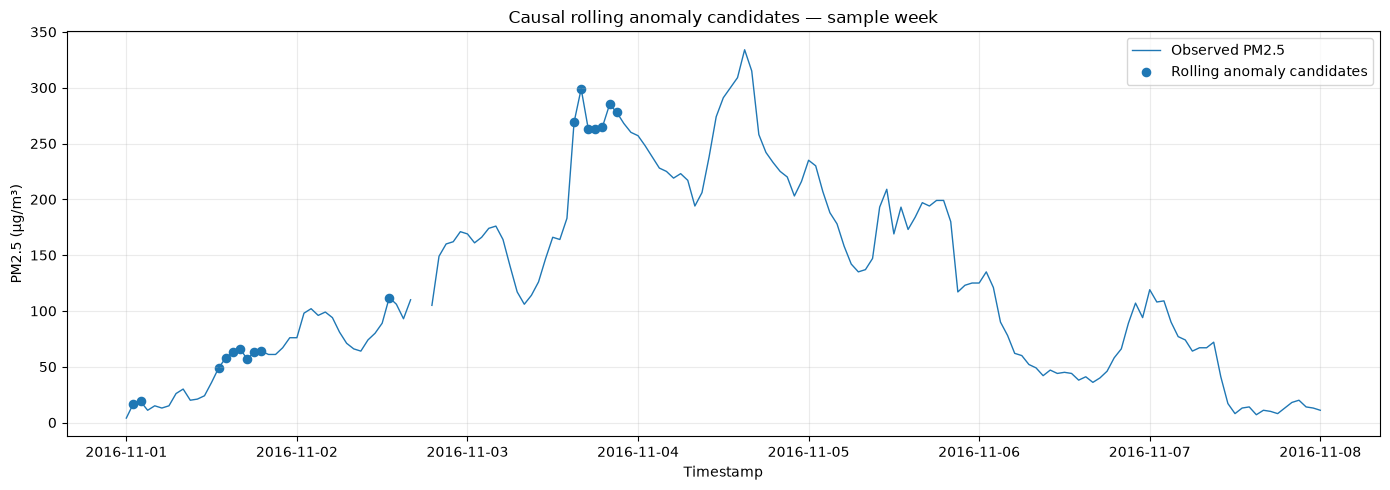

Rows in selected plotting period: 169
Candidate anomalies in selected period: 17


In [5]:
# 3.2 — Visualize a sample of rolling anomaly candidates

plot_start = pd.Timestamp("2016-11-01")
plot_end = pd.Timestamp("2016-11-08")

plot_mask = raw_df["timestamp"].between(plot_start, plot_end)
plot_df = raw_df.loc[plot_mask]

candidate_df = plot_df.loc[plot_df["rolling_anomaly"]]

plt.figure(figsize=(14, 5))
plt.plot(
    plot_df["timestamp"],
    plot_df["PM2.5"],
    label="Observed PM2.5",
    linewidth=1
)
plt.scatter(
    candidate_df["timestamp"],
    candidate_df["PM2.5"],
    label="Rolling anomaly candidates",
    s=35
)

plt.title("Causal rolling anomaly candidates — sample week")
plt.xlabel("Timestamp")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

print("Rows in selected plotting period:", len(plot_df))
print("Candidate anomalies in selected period:", len(candidate_df))

## 4 — Multivariate Anomaly Detection with Isolation Forest

Isolation Forest is an unsupervised machine-learning method that identifies
observations that are relatively easy to isolate through random feature
splits.

The detector uses pollutant and meteorological variables together. Missing
features are imputed using medians fitted on the training partition only,
and the fitted preprocessing transformations are reused for validation
and test observations.

The model is fitted on training data only. A contamination setting of 1%
is used as an initial exploratory assumption; it is not an estimate of the
true proportion of anomalous observations. Results will be interpreted as
candidate anomalies, not verified errors.

In [6]:
# 4.1 — Fit Isolation Forest on the training partition only

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest

CONTAMINATION = 0.01

# The detector uses only the original numerical measurements.
X_train_raw = train_df[feature_columns].copy()
X_all_raw = raw_df[feature_columns].copy()

# Fit imputation on training data only.
anomaly_imputer = SimpleImputer(strategy="median")
X_train_imputed = anomaly_imputer.fit_transform(X_train_raw)
X_all_imputed = anomaly_imputer.transform(X_all_raw)

# Robust scaling reduces the influence of extreme magnitudes.
anomaly_scaler = RobustScaler()
X_train_scaled = anomaly_scaler.fit_transform(X_train_imputed)
X_all_scaled = anomaly_scaler.transform(X_all_imputed)

isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=CONTAMINATION,
    random_state=42,
    n_jobs=-1
)

isolation_forest.fit(X_train_scaled)

# Isolation Forest returns -1 for candidate anomalies and 1 otherwise.
all_if_predictions = isolation_forest.predict(X_all_scaled)
all_if_scores = isolation_forest.decision_function(X_all_scaled)

raw_df["isolation_forest_candidate"] = (
    all_if_predictions == -1
)
raw_df["isolation_forest_score"] = all_if_scores

print("Isolation Forest fitted")
print("-" * 55)
print("Training rows:", len(train_df))
print("Feature count:", len(feature_columns))
print("Trees:", 200)
print("Contamination setting:", CONTAMINATION)
print("Training matrix finite:",
      bool(np.isfinite(X_train_scaled).all()))
print("All transformed observations finite:",
      bool(np.isfinite(X_all_scaled).all()))
print("Total IF candidates:",
      int(raw_df["isolation_forest_candidate"].sum()))

Isolation Forest fitted
-------------------------------------------------------
Training rows: 24544
Feature count: 11
Trees: 200
Contamination setting: 0.01
Training matrix finite: True
All transformed observations finite: True
Total IF candidates: 426


In [7]:
# 4.2 — Compare anomaly candidate rates across partitions

partition_masks = {
    "Training": train_mask,
    "Validation": val_mask,
    "Test": test_mask
}

partition_rows = []

for partition_name, mask in partition_masks.items():
    part = raw_df.loc[mask]

    observed_pm25 = part["PM2.5"].notna()

    partition_rows.append({
        "Partition": partition_name,
        "Rows": len(part),
        "Observed_PM2.5": int(observed_pm25.sum()),
        "Rolling_Candidates": int(
            (part["rolling_anomaly"] & observed_pm25).sum()
        ),
        "Isolation_Forest_Candidates": int(
            (part["isolation_forest_candidate"] & observed_pm25).sum()
        ),
        "Rolling_Rate_Percent": (
            100 * part.loc[observed_pm25, "rolling_anomaly"].mean()
            if observed_pm25.any() else np.nan
        ),
        "IF_Rate_Percent": (
            100 * part.loc[
                observed_pm25, "isolation_forest_candidate"
            ].mean()
            if observed_pm25.any() else np.nan
        )
    })

partition_summary = pd.DataFrame(partition_rows)
display(partition_summary.round(3))

,Partition,Rows,Observed_PM2.5,Rolling_Candidates,Isolation_Forest_Candidates,Rolling_Rate_Percent,IF_Rate_Percent
0,Training,24544,23814,2639,246,11.082,1.033
1,Validation,5260,5152,531,83,10.307,1.611
2,Test,5260,5173,679,97,13.126,1.875


## 5 — Abrupt-Change Detection

Hourly PM2.5 differences are examined to identify unusually large changes
between consecutive observations.

The absolute hourly change threshold is defined using the 99.5th percentile
of observed absolute changes in the training partition. The same threshold
is applied to all partitions.

A large change may represent a genuine pollution event, a measurement
issue, or another process. It is treated as a candidate for investigation.

In [8]:
# 3.1 — Compute causal rolling robust scores for PM2.5

ROLLING_WINDOW = 24
MIN_HISTORY = 12
ROBUST_Z_THRESHOLD = 3.5

pm25 = raw_df["PM2.5"].astype(float)

# Shift by one so the current reading is not part of its own reference.
past_pm25 = pm25.shift(1)

rolling_median = past_pm25.rolling(
    window=ROLLING_WINDOW,
    min_periods=MIN_HISTORY
).median()

def median_absolute_deviation(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return np.nan

    median = np.median(values)
    return np.median(np.abs(values - median))

rolling_mad = past_pm25.rolling(
    window=ROLLING_WINDOW,
    min_periods=MIN_HISTORY
).apply(median_absolute_deviation, raw=True)

# Avoid dividing by zero when recent values have zero MAD.
mad_safe = rolling_mad.where(rolling_mad > 0)

raw_df["PM2.5_rolling_median_24h"] = rolling_median
raw_df["PM2.5_rolling_MAD_24h"] = rolling_mad

raw_df["PM2.5_robust_z"] = (
    0.6745 * (pm25 - rolling_median) / mad_safe
)

raw_df["rolling_anomaly"] = (
    raw_df["PM2.5_robust_z"].abs() >= ROBUST_Z_THRESHOLD
)

raw_df.loc[
    raw_df["PM2.5"].isna(),
    "rolling_anomaly"
] = False

raw_df["rolling_anomaly"] = raw_df["rolling_anomaly"].astype(bool)

valid_rolling_scores = raw_df["PM2.5_robust_z"].dropna()

print("Rolling anomaly detection")
print("-" * 55)
print("Window (hours):", ROLLING_WINDOW)
print("Minimum historical readings:", MIN_HISTORY)
print("Robust score threshold:", ROBUST_Z_THRESHOLD)
print("Rows with a usable robust score:", len(valid_rolling_scores))
print("Candidate anomalies:",
      int(raw_df["rolling_anomaly"].sum()))
print("Candidate rate among observed PM2.5 values:",
      round(
          100 * raw_df.loc[
              raw_df["PM2.5"].notna(), "rolling_anomaly"
          ].mean(),
          3
      ), "%")

display(
    raw_df.loc[
        raw_df["rolling_anomaly"],
        [
            "timestamp", "PM2.5",
            "PM2.5_rolling_median_24h",
            "PM2.5_rolling_MAD_24h",
            "PM2.5_robust_z"
        ]
    ].head(15)
)

Rolling anomaly detection
-------------------------------------------------------
Window (hours): 24
Minimum historical readings: 12
Robust score threshold: 3.5
Rows with a usable robust score: 33967
Candidate anomalies: 3849
Candidate rate among observed PM2.5 values: 11.274 %


,timestamp,PM2.5,PM2.5_rolling_median_24h,PM2.5_rolling_MAD_24h,PM2.5_robust_z
18,2013-03-01 18:00:00,11.0,3.5,0.5,10.117500
23,2013-03-01 23:00:00,24.0,6.0,3.0,4.047000
24,2013-03-02 00:00:00,22.0,6.0,3.0,3.597333
39,2013-03-02 15:00:00,37.0,11.0,3.5,5.010571
45,2013-03-02 21:00:00,74.0,16.5,9.5,4.082500
48,2013-03-03 00:00:00,112.0,23.5,17.0,3.511368
95,2013-03-04 23:00:00,58.0,15.5,7.0,4.095179
96,2013-03-05 00:00:00,71.0,15.5,7.0,5.347821
97,2013-03-05 01:00:00,91.0,15.5,7.0,7.274964
98,2013-03-05 02:00:00,100.0,15.5,7.0,8.142179


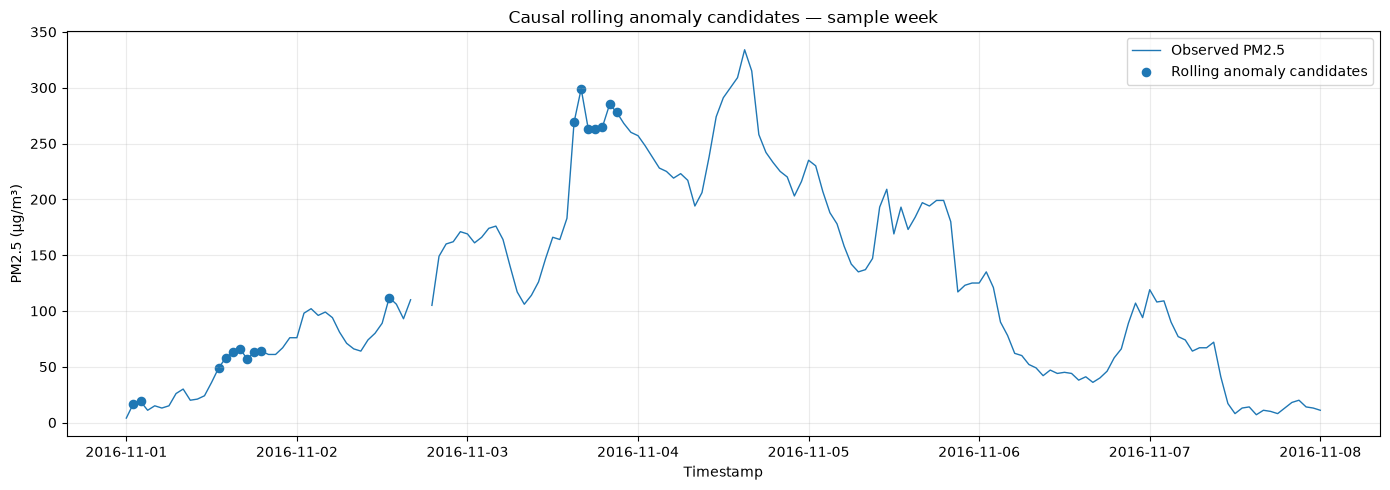

Rows in selected plotting period: 169
Candidate anomalies in selected period: 17


In [9]:
# 3.2 — Visualize a sample of rolling anomaly candidates

plot_start = pd.Timestamp("2016-11-01")
plot_end = pd.Timestamp("2016-11-08")

plot_mask = raw_df["timestamp"].between(plot_start, plot_end)
plot_df = raw_df.loc[plot_mask]

candidate_df = plot_df.loc[plot_df["rolling_anomaly"]]

plt.figure(figsize=(14, 5))
plt.plot(
    plot_df["timestamp"],
    plot_df["PM2.5"],
    label="Observed PM2.5",
    linewidth=1
)
plt.scatter(
    candidate_df["timestamp"],
    candidate_df["PM2.5"],
    label="Rolling anomaly candidates",
    s=35
)

plt.title("Causal rolling anomaly candidates — sample week")
plt.xlabel("Timestamp")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

print("Rows in selected plotting period:", len(plot_df))
print("Candidate anomalies in selected period:", len(candidate_df))

## 5 — Abrupt-Change Detection

Hourly PM2.5 differences are examined to identify unusually large changes
between consecutive observations.

The absolute hourly change threshold is defined using the 99.5th percentile
of observed absolute changes in the training partition. The same threshold
is applied to all partitions.

A large change may represent a genuine pollution event, a measurement
issue, or another process. It is treated as a candidate for investigation.

In [10]:
# 5.1 — Learn an abrupt-change threshold from training observations

raw_df["PM2.5_hourly_change"] = raw_df["PM2.5"].diff()
raw_df["PM2.5_absolute_change"] = (
    raw_df["PM2.5_hourly_change"].abs()
)

train_change_mask = (
    raw_df["timestamp"].le(TRAIN_END)
    & raw_df["PM2.5_absolute_change"].notna()
)

if train_change_mask.sum() == 0:
    raise ValueError("No observed training changes available.")

CHANGE_QUANTILE = 0.995

change_threshold = float(
    raw_df.loc[
        train_change_mask, "PM2.5_absolute_change"
    ].quantile(CHANGE_QUANTILE)
)

raw_df["abrupt_change_candidate"] = (
    raw_df["PM2.5_absolute_change"] > change_threshold
)

print("Abrupt-change detection")
print("-" * 55)
print("Training absolute-change observations:",
      int(train_change_mask.sum()))
print("Quantile used:", CHANGE_QUANTILE)
print("Learned threshold (µg/m³ per hour):",
      round(change_threshold, 4))
print("Total abrupt-change candidates:",
      int(raw_df["abrupt_change_candidate"].sum()))

display(
    raw_df.loc[
        raw_df["abrupt_change_candidate"],
        [
            "timestamp", "PM2.5",
            "PM2.5_hourly_change",
            "PM2.5_absolute_change"
        ]
    ].head(15)
)

Abrupt-change detection
-------------------------------------------------------
Training absolute-change observations: 23683
Quantile used: 0.995
Learned threshold (µg/m³ per hour): 102.0
Total abrupt-change candidates: 182


,timestamp,PM2.5,PM2.5_hourly_change,PM2.5_absolute_change
179,2013-03-08 11:00:00,219.0,-107.0,107.0
180,2013-03-08 12:00:00,104.0,-115.0,115.0
183,2013-03-08 15:00:00,330.0,146.0,146.0
184,2013-03-08 16:00:00,172.0,-158.0,158.0
347,2013-03-15 11:00:00,3.0,-170.0,170.0
348,2013-03-15 12:00:00,110.0,107.0,107.0
349,2013-03-15 13:00:00,227.0,117.0,117.0
410,2013-03-18 02:00:00,308.0,-155.0,155.0
411,2013-03-18 03:00:00,36.0,-272.0,272.0
513,2013-03-22 09:00:00,146.0,136.0,136.0


## 6 — Detector Agreement and Candidate Review

The three methods capture different forms of unusual behaviour:

- Rolling robust deviation: unusual PM2.5 relative to recent history.
- Isolation Forest: unusual combinations of pollutant and weather variables.
- Abrupt-change detection: unusually large hour-to-hour PM2.5 changes.

Agreement between methods can help prioritize observations for review, but
it does not establish that an observation is erroneous or that a pollution
event has been independently verified.

In [11]:
# 6.1 — Compare the three anomaly detectors

detector_columns = [
    "rolling_anomaly",
    "isolation_forest_candidate",
    "abrupt_change_candidate"
]

raw_df["detector_agreement_count"] = (
    raw_df[detector_columns].sum(axis=1)
)

raw_df["flagged_by_multiple_detectors"] = (
    raw_df["detector_agreement_count"] >= 2
)

observed_pm25 = raw_df["PM2.5"].notna()

detector_summary = pd.DataFrame([
    {
        "Detector": "Rolling robust deviation",
        "Candidate_Count": int(
            (raw_df["rolling_anomaly"] & observed_pm25).sum()
        )
    },
    {
        "Detector": "Isolation Forest",
        "Candidate_Count": int(
            (
                raw_df["isolation_forest_candidate"]
                & observed_pm25
            ).sum()
        )
    },
    {
        "Detector": "Abrupt hourly change",
        "Candidate_Count": int(
            (
                raw_df["abrupt_change_candidate"]
                & observed_pm25
            ).sum()
        )
    },
    {
        "Detector": "Flagged by 2+ detectors",
        "Candidate_Count": int(
            (
                raw_df["flagged_by_multiple_detectors"]
                & observed_pm25
            ).sum()
        )
    },
    {
        "Detector": "Flagged by all 3 detectors",
        "Candidate_Count": int(
            (
                raw_df["detector_agreement_count"].eq(3)
                & observed_pm25
            ).sum()
        )
    }
])

display(detector_summary)

,Detector,Candidate_Count
0,Rolling robust deviation,3849
1,Isolation Forest,426
2,Abrupt hourly change,182
3,Flagged by 2+ detectors,174
4,Flagged by all 3 detectors,15


In [12]:
# 6.2 — Review observations with agreement between detectors

candidate_columns = [
    "timestamp",
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM",
    "PM2.5_robust_z",
    "PM2.5_absolute_change",
    "isolation_forest_score",
    "detector_agreement_count"
]

review_candidates = raw_df.loc[
    raw_df["flagged_by_multiple_detectors"] & observed_pm25,
    candidate_columns
].copy()

review_candidates = review_candidates.sort_values(
    ["detector_agreement_count", "PM2.5_absolute_change"],
    ascending=[False, False]
)

print("Candidate observations flagged by at least two detectors:",
      len(review_candidates))

display(review_candidates.head(25))

Candidate observations flagged by at least two detectors: 174


,timestamp,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,PM2.5_robust_z,PM2.5_absolute_change,isolation_forest_score,detector_agreement_count
25778,2016-02-08 02:00:00,898.0,NaN,341.0,92.0,1900.0,10.0,-1.600,1009.9,-15.1,0.0,1.1,42.843241,404.0,-0.007107,3
25777,2016-02-08 01:00:00,494.0,637.0,192.0,86.0,1400.0,7.0,-1.700,1010.5,-15.2,0.0,1.5,32.198500,342.0,-0.058022,3
34297,2017-01-28 01:00:00,576.0,815.0,155.0,94.0,2100.0,80.0,-0.525,1020.0,-15.7,0.0,0.8,12.935946,271.0,-0.069390,3
34303,2017-01-28 07:00:00,462.0,491.0,104.0,83.0,2800.0,66.0,-2.800,1018.0,-11.1,0.0,1.8,4.290262,235.0,-0.027550,3
7699,2014-01-15 19:00:00,357.0,470.0,196.0,167.0,4500.0,1.0,-1.900,1022.5,-8.9,0.0,1.7,7.873755,230.0,-0.064465,3
25779,2016-02-08 03:00:00,713.0,884.0,229.0,91.0,2100.0,10.0,-2.600,1008.8,-14.4,0.0,0.6,26.682426,185.0,-0.058704,3
25784,2016-02-08 08:00:00,374.0,501.0,89.0,55.0,2800.0,30.0,4.800,1008.8,-12.7,0.0,4.2,10.431221,170.0,-0.031555,3
17281,2015-02-19 01:00:00,281.0,392.0,128.0,41.0,900.0,46.0,2.000,1022.0,-10.9,0.0,1.6,32.498636,149.0,-0.007795,3
16455,2015-01-15 15:00:00,497.0,578.0,51.0,214.0,7900.0,2.0,2.000,1022.0,-7.4,0.0,1.1,8.050011,145.0,-0.073356,3
24093,2015-11-29 21:00:00,369.0,405.0,2.0,198.0,8800.0,12.0,-2.000,1023.3,-2.6,0.0,1.0,3.621000,143.0,-0.035180,3


,Observed_PM25,Rolling_Candidates,IF_Candidates,Abrupt_Change_Candidates,Multiple_Detector_Candidates,Rolling_Rate_Percent,IF_Rate_Percent
timestamp,,,,,,,
2015-09-01,707,74,0,4,3,10.467,0.000
2015-10-01,740,76,0,2,2,10.270,0.000
2015-11-01,703,70,16,7,5,9.957,2.276
2015-12-01,735,119,63,13,24,16.190,8.571
2016-01-01,734,98,12,5,8,13.351,1.635
2016-02-01,692,98,9,5,9,14.162,1.301
2016-03-01,710,82,4,4,3,11.549,0.563
2016-04-01,684,59,0,2,2,8.626,0.000
2016-05-01,737,53,0,4,3,7.191,0.000


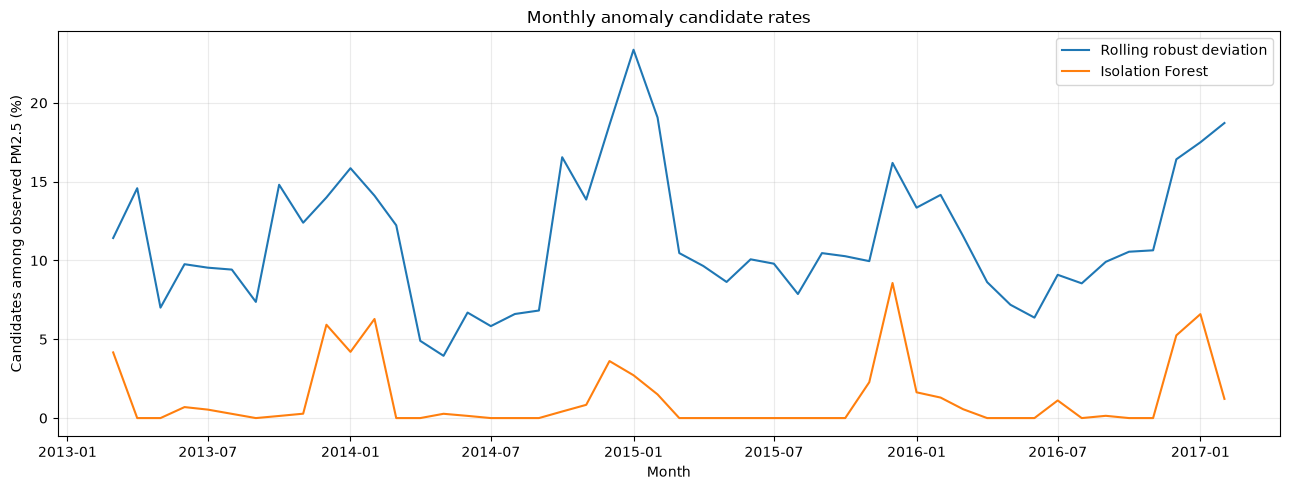

In [13]:
# 7.1 — Monthly anomaly candidate counts and rates

monthly = raw_df.set_index("timestamp").resample("MS").agg(
    Observed_PM25=("PM2.5", "count"),
    Rolling_Candidates=("rolling_anomaly", "sum"),
    IF_Candidates=("isolation_forest_candidate", "sum"),
    Abrupt_Change_Candidates=("abrupt_change_candidate", "sum"),
    Multiple_Detector_Candidates=("flagged_by_multiple_detectors", "sum")
)

monthly["Rolling_Rate_Percent"] = (
    100 * monthly["Rolling_Candidates"]
    / monthly["Observed_PM25"].replace(0, np.nan)
)

monthly["IF_Rate_Percent"] = (
    100 * monthly["IF_Candidates"]
    / monthly["Observed_PM25"].replace(0, np.nan)
)

display(monthly.round(3).tail(18))

plt.figure(figsize=(13, 5))
plt.plot(
    monthly.index,
    monthly["Rolling_Rate_Percent"],
    label="Rolling robust deviation"
)
plt.plot(
    monthly.index,
    monthly["IF_Rate_Percent"],
    label="Isolation Forest"
)
plt.title("Monthly anomaly candidate rates")
plt.xlabel("Month")
plt.ylabel("Candidates among observed PM2.5 (%)")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [14]:
# 8.1 — Export anomaly candidates and summary reports

from pathlib import Path

project_root = Path(r"C:\UrbanPulse-AI")
report_dir = project_root / "reports"
report_dir.mkdir(parents=True, exist_ok=True)

anomaly_output_columns = [
    "timestamp",
    *feature_columns,
    "PM2.5_rolling_median_24h",
    "PM2.5_rolling_MAD_24h",
    "PM2.5_robust_z",
    "rolling_anomaly",
    "PM2.5_hourly_change",
    "PM2.5_absolute_change",
    "abrupt_change_candidate",
    "isolation_forest_score",
    "isolation_forest_candidate",
    "detector_agreement_count",
    "flagged_by_multiple_detectors"
]

anomaly_output_path = report_dir / "anomaly_detection_results.csv"
monthly_output_path = report_dir / "anomaly_detection_monthly_summary.csv"
summary_output_path = report_dir / "anomaly_detection_detector_summary.csv"

raw_df[anomaly_output_columns].to_csv(
    anomaly_output_path,
    index=False
)

monthly.to_csv(monthly_output_path)
detector_summary.to_csv(summary_output_path, index=False)

print("Saved anomaly-detection outputs:")
print(anomaly_output_path)
print(monthly_output_path)
print(summary_output_path)

Saved anomaly-detection outputs:
C:\UrbanPulse-AI\reports\anomaly_detection_results.csv
C:\UrbanPulse-AI\reports\anomaly_detection_monthly_summary.csv
C:\UrbanPulse-AI\reports\anomaly_detection_detector_summary.csv


In [15]:
# Rebuild the monthly anomaly summary using observed PM2.5 rows only

monthly_source = raw_df.set_index("timestamp").copy()
monthly_source["observed_pm25"] = monthly_source["PM2.5"].notna()

monthly_summary = monthly_source.resample("MS").agg(
    Observed_PM25=("observed_pm25", "sum"),
    Rolling_Candidates=("rolling_anomaly", lambda s: int(
        s[monthly_source.loc[s.index, "observed_pm25"]].sum()
    )),
    IF_Candidates=("isolation_forest_candidate", lambda s: int(
        s[monthly_source.loc[s.index, "observed_pm25"]].sum()
    )),
    Abrupt_Change_Candidates=("abrupt_change_candidate", lambda s: int(
        s[monthly_source.loc[s.index, "observed_pm25"]].sum()
    )),
    Multiple_Detector_Candidates=("flagged_by_multiple_detectors", lambda s: int(
        s[monthly_source.loc[s.index, "observed_pm25"]].sum()
    )),
)

for column in [
    "Rolling_Candidates",
    "IF_Candidates",
    "Abrupt_Change_Candidates",
    "Multiple_Detector_Candidates",
]:
    monthly_summary[column.replace("_Candidates", "_Rate_Percent")] = (
        100 * monthly_summary[column]
        / monthly_summary["Observed_PM25"].replace(0, np.nan)
    )

display(monthly_summary.round(3))

monthly_summary.to_csv(
    r"C:\UrbanPulse-AI\reports\anomaly_detection_monthly_summary.csv"
)

,Observed_PM25,Rolling_Candidates,IF_Candidates,Abrupt_Change_Candidates,Multiple_Detector_Candidates,Rolling_Rate_Percent,IF_Rate_Percent,Abrupt_Change_Rate_Percent,Multiple_Detector_Rate_Percent
timestamp,,,,,,,,,
2013-03-01,744,85,31,10,5,11.425,4.167,1.344,0.672
2013-04-01,720,105,0,1,1,14.583,0.000,0.139,0.139
2013-05-01,742,52,0,8,5,7.008,0.000,1.078,0.674
2013-06-01,717,70,5,6,3,9.763,0.697,0.837,0.418
2013-07-01,744,71,4,2,2,9.543,0.538,0.269,0.269
2013-08-01,743,70,2,2,0,9.421,0.269,0.269,0.000
2013-09-01,719,53,0,0,0,7.371,0.000,0.000,0.000
2013-10-01,743,110,1,2,2,14.805,0.135,0.269,0.269
2013-11-01,718,89,2,3,1,12.396,0.279,0.418,0.139


In [16]:
# Audit monthly PM2.5 observation counts against the raw dataset
audit = raw_df.set_index("timestamp")["PM2.5"].resample("MS").agg(
    Total_Hours="size",
    Observed_PM25="count",
)

audit["Missing_PM25"] = audit["Total_Hours"] - audit["Observed_PM25"]

print("Total rows:", len(raw_df))
print("Total missing PM2.5:", raw_df["PM2.5"].isna().sum())
print("Monthly audit totals:")
display(audit.loc["2014-01":"2015-01"])

print("\nOverall monthly totals:")
print(audit[["Total_Hours", "Observed_PM25", "Missing_PM25"]].sum())

print("\nDoes the audit agree with the raw data?")
print("Monthly rows sum to raw row count:",
      audit["Total_Hours"].sum() == len(raw_df))
print("Monthly observed counts match raw non-null count:",
      audit["Observed_PM25"].sum() == raw_df["PM2.5"].count())

Total rows: 35064
Total missing PM2.5: 925
Monthly audit totals:


,Total_Hours,Observed_PM25,Missing_PM25
timestamp,,,
2014-01-01,744,738,6
2014-02-01,672,652,20
2014-03-01,744,744,0
2014-04-01,720,653,67
2014-05-01,744,734,10
2014-06-01,720,717,3
2014-07-01,744,737,7
2014-08-01,744,742,2
2014-09-01,720,718,2



Overall monthly totals:
Total_Hours      35064
Observed_PM25    34139
Missing_PM25       925
dtype: int64

Does the audit agree with the raw data?
Monthly rows sum to raw row count: True
Monthly observed counts match raw non-null count: True


In [17]:
import numpy as np
import pandas as pd
from pathlib import Path

monthly_source = raw_df.copy()
monthly_source["timestamp"] = pd.to_datetime(monthly_source["timestamp"])
monthly_source = monthly_source.set_index("timestamp").sort_index()

observed = monthly_source["PM2.5"].notna()

flag_columns = {
    "Rolling_Candidates": "rolling_anomaly",
    "IF_Candidates": "isolation_forest_candidate",
    "Abrupt_Change_Candidates": "abrupt_change_candidate",
    "Multiple_Detector_Candidates": "flagged_by_multiple_detectors",
}

monthly_summary = pd.DataFrame(index=monthly_source.resample("MS").size().index)

monthly_summary["Total_Hours"] = monthly_source["PM2.5"].resample("MS").size()
monthly_summary["Observed_PM25"] = (
    monthly_source["PM2.5"].resample("MS").count()
)

for output_col, flag_col in flag_columns.items():
    if flag_col not in monthly_source.columns:
        raise KeyError(
            f"Missing detector column: {flag_col}. "
            "Check the actual flag-column names in raw_df."
        )

    flags = monthly_source[flag_col].fillna(False).astype(bool)
    monthly_summary[output_col] = (
        (flags & observed).astype(int).resample("MS").sum()
    )

for output_col in flag_columns:
    rate_col = output_col.replace("_Candidates", "_Rate_Percent")
    monthly_summary[rate_col] = (
        100 * monthly_summary[output_col]
        / monthly_summary["Observed_PM25"].replace(0, np.nan)
    )

display(monthly_summary.round(3))

report_path = Path(r"C:\UrbanPulse-AI\reports")
report_path.mkdir(parents=True, exist_ok=True)

monthly_summary.to_csv(
    report_path / "anomaly_detection_monthly_summary.csv"
)

print("Saved corrected monthly summary.")
print("Observed PM2.5 total:", monthly_summary["Observed_PM25"].sum())
print("Monthly hours total:", monthly_summary["Total_Hours"].sum())

,Total_Hours,Observed_PM25,Rolling_Candidates,IF_Candidates,Abrupt_Change_Candidates,Multiple_Detector_Candidates,Rolling_Rate_Percent,IF_Rate_Percent,Abrupt_Change_Rate_Percent,Multiple_Detector_Rate_Percent
timestamp,,,,,,,,,,
2013-03-01,744,744,85,31,10,5,11.425,4.167,1.344,0.672
2013-04-01,720,720,105,0,1,1,14.583,0.000,0.139,0.139
2013-05-01,744,742,52,0,8,5,7.008,0.000,1.078,0.674
2013-06-01,720,717,70,5,6,3,9.763,0.697,0.837,0.418
2013-07-01,744,744,71,4,2,2,9.543,0.538,0.269,0.269
2013-08-01,744,743,70,2,2,0,9.421,0.269,0.269,0.000
2013-09-01,720,719,53,0,0,0,7.371,0.000,0.000,0.000
2013-10-01,744,743,110,1,2,2,14.805,0.135,0.269,0.269
2013-11-01,720,718,89,2,3,1,12.396,0.279,0.418,0.139


Saved corrected monthly summary.
Observed PM2.5 total: 34139
Monthly hours total: 35064


In [18]:
from pathlib import Path
import pandas as pd

data_dir = Path(
    r"C:\UrbanPulse-AI\data\raw\beijing\extracted"
)

station_files = sorted(
    data_dir.rglob("PRSA_Data_*_20130301-20170228.csv")
)

print("Station CSV files found:", len(station_files))
for file in station_files:
    print(file.name, "|", f"{file.stat().st_size:,} bytes")

if station_files:
    sample = pd.read_csv(station_files[0], nrows=5)
    print("\nSample file:", station_files[0].name)
    print("Columns:", sample.columns.tolist())
    display(sample.head())

Station CSV files found: 12
PRSA_Data_Aotizhongxin_20130301-20170228.csv | 2,835,916 bytes
PRSA_Data_Changping_20130301-20170228.csv | 2,722,295 bytes
PRSA_Data_Dingling_20130301-20170228.csv | 2,675,856 bytes
PRSA_Data_Dongsi_20130301-20170228.csv | 2,636,684 bytes
PRSA_Data_Guanyuan_20130301-20170228.csv | 2,695,860 bytes
PRSA_Data_Gucheng_20130301-20170228.csv | 2,654,625 bytes
PRSA_Data_Huairou_20130301-20170228.csv | 2,641,027 bytes
PRSA_Data_Nongzhanguan_20130301-20170228.csv | 2,839,705 bytes
PRSA_Data_Shunyi_20130301-20170228.csv | 2,620,654 bytes
PRSA_Data_Tiantan_20130301-20170228.csv | 2,655,061 bytes
PRSA_Data_Wanliu_20130301-20170228.csv | 2,659,544 bytes
PRSA_Data_Wanshouxigong_20130301-20170228.csv | 2,871,076 bytes

Sample file: PRSA_Data_Aotizhongxin_20130301-20170228.csv
Columns: ['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4,4,4,7,300,77,-0.7,1023.0,-18.8,0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8,8,4,7,300,77,-1.1,1023.2,-18.2,0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7,7,5,10,300,73,-1.1,1023.5,-18.2,0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6,6,11,11,300,72,-1.4,1024.5,-19.4,0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3,3,12,12,300,72,-2.0,1025.2,-19.5,0,N,2.0,Aotizhongxin
